# Phase D: Das erste LSTM

Schritte 12 bis 14 aus `LERNPLAN.md`.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
METER_DIR = ROOT / "data" / "processed" / "real_meters"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 12: PyTorch-Grundlagen

Ein LSTM liest einen Tag Stunde für Stunde und trägt dabei ein Gedächtnis mit: ein paar Zahlen, die nach jeder Stunde neu geschrieben werden. Gerechnet wird auf der Grafikkarte, wenn es eine gibt:

In [2]:
import torch

geraet = "cuda" if torch.cuda.is_available() else "cpu"
geraet

'cuda'

In [3]:
LERNPFAD = ROOT / "data" / "processed" / "lernpfad"
X_alle = np.load(LERNPFAD / "X_tage.npy")
info = pd.read_csv(LERNPFAD / "info_tage.csv", parse_dates=["tag"])
X_alle.shape

(24684, 24, 4)

Der Tensor aus Phase C. Ein einzelner Tag als PyTorch-Tensor. PyTorch will immer einen Stapel, auch wenn er nur einen Tag enthält:

In [4]:
ein_tag = torch.tensor(X_alle[:1], dtype=torch.float32)
ein_tag.shape

torch.Size([1, 24, 4])

Ein untrainiertes LSTM mit 4 Eingängen (unsere Kanäle) und 8 Gedächtniszahlen:

In [5]:
lstm = torch.nn.LSTM(input_size=4, hidden_size=8, batch_first=True)
ausgabe, (h, c) = lstm(ein_tag)
ausgabe.shape

torch.Size([1, 24, 8])

1 Tag × 24 Stunden × 8 Gedächtniszahlen, also 8 Zahlen nach jeder Stunde. Die 8 ist die Größe des Gedächtnisses, nicht die Zahl der Tage. Was steckt in `h`?

In [6]:
print(ausgabe[0, -1])
print(h[0, 0])

tensor([ 9.2459e-01, -1.6317e-07, -9.9968e-01,  2.0635e-03, -4.5477e-06,
         1.7771e-03,  8.4814e-01, -2.2330e-06], grad_fn=<SelectBackward0>)
tensor([ 9.2459e-01, -1.6317e-07, -9.9968e-01,  2.0635e-03, -4.5477e-06,
         1.7771e-03,  8.4814e-01, -2.2330e-06], grad_fn=<SelectBackward0>)


Dieselben 8 Zahlen: `h` ist das Gedächtnis nach der letzten Stunde, also die Zusammenfassung des ganzen Tages.

Für eine Vorhersage kommt hinter das LSTM eine lineare Schicht, die aus dem Gedächtnis 24 Zahlen macht, den Rücklauf von morgen:

In [7]:
class Vorhersage(torch.nn.Module):
    def __init__(self, kanaele, gedaechtnis):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=kanaele, hidden_size=gedaechtnis, batch_first=True)
        self.ausgang = torch.nn.Linear(gedaechtnis, 24)

    def forward(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.ausgang(h[-1])

In [8]:
modell = Vorhersage(kanaele=4, gedaechtnis=8)
modell(ein_tag).shape

torch.Size([1, 24])

1 Tag, 24 Werte. Noch Unsinn, weil untrainiert.

### Daten vorbereiten

Dieselbe Aufteilung wie in Phase C (gleicher Seed, also gleiche Wochen), Paare aus heute und morgen, Skalierung nur aus dem Training:

In [9]:
info["woche"] = info["tag"].dt.to_period("W").astype(str)
test = info["tag"] >= "2024-06-01"
wochen = info.loc[~test, "woche"].unique()
np.random.seed(0)
val_wochen = np.random.choice(wochen, size=int(0.1 * len(wochen)), replace=False)
val = info["woche"].isin(val_wochen) & ~test
train = ~test & ~val
train.sum(), val.sum(), test.sum()

(np.int64(18689), np.int64(1511), np.int64(4484))

In [10]:
naechster = info.groupby("zaehler")["tag"].shift(-1)
paar = (naechster - info["tag"]) == pd.Timedelta(days=1)
heute = np.where(paar)[0]
morgen = heute + 1

In [11]:
mittel = X_alle[train.values].mean(axis=(0, 1))
streuung = X_alle[train.values].std(axis=(0, 1))
X_s = (X_alle - mittel) / streuung

Pro Stunde die 4 Kanäle von heute und als fünfter die Außentemperatur von morgen. Im Einsatz gäbe es dafür nur die Wettervorhersage, wie viel das ausmacht, steht weiter unten.

In [12]:
eingabe = np.concatenate([X_s[heute], X_s[morgen][:, :, 3:4]], axis=2)
ziel = X_s[morgen][:, :, 0]

ist_train = train.values[morgen]
ist_val = val.values[morgen]
ist_test = test.values[morgen]

eingabe.shape

(24236, 24, 5)

24.236 Paare × 24 Stunden × 5 Kanäle.

### Training

Die Schleife: vorhersagen, Fehler messen (MSE), zurückrechnen, welche Richtung jedes Gewicht braucht (`backward`), Gewichte ein kleines Stück korrigieren (`step`). Das passiert in Stapeln von 256 Tagen, ein Durchgang durch alle Stapel ist eine Runde. Erst mal klein: 32 Gedächtniszahlen, 30 Runden.

In [13]:
x_train = torch.tensor(eingabe[ist_train], dtype=torch.float32, device=geraet)
y_train = torch.tensor(ziel[ist_train], dtype=torch.float32, device=geraet)
x_val = torch.tensor(eingabe[ist_val], dtype=torch.float32, device=geraet)
y_val = torch.tensor(ziel[ist_val], dtype=torch.float32, device=geraet)

In [14]:
torch.manual_seed(0)
modell = Vorhersage(kanaele=5, gedaechtnis=32).to(geraet)
fehler = torch.nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)

In [15]:
verlauf = []
for runde in range(30):
    modell.train()
    reihenfolge = torch.randperm(len(x_train), device=geraet)
    for start in range(0, len(x_train), 256):
        stapel = reihenfolge[start:start + 256]
        optimierer.zero_grad()
        loss = fehler(modell(x_train[stapel]), y_train[stapel])
        loss.backward()
        optimierer.step()

    modell.eval()
    with torch.no_grad():
        f_train = fehler(modell(x_train), y_train).item()
        f_val = fehler(modell(x_val), y_val).item()
    verlauf.append({"runde": runde, "training": f_train, "validierung": f_val})
    print(runde, round(f_train, 4), round(f_val, 4))

0 0.4098 0.3836
1 0.3186 0.2902
2 0.3073 0.2779
3 0.3021 0.2734


4 0.2983 0.2693
5 0.2937 0.2645
6 0.287 0.2577
7 0.2825 0.2537


8 0.2779 0.2505
9 0.2774 0.2495
10 0.2747 0.2478
11 0.2731 0.2461


12 0.273 0.2464
13 0.2732 0.2489
14 0.2706 0.2446
15 0.2695 0.244


16 0.2684 0.2429
17 0.2682 0.2431
18 0.2663 0.2405
19 0.2656 0.2411


20 0.2652 0.2402
21 0.2638 0.2394
22 0.2626 0.238
23 0.2616 0.2378


24 0.2606 0.2372
25 0.2601 0.2368
26 0.2598 0.2372
27 0.2593 0.2374


28 0.2588 0.2368
29 0.2572 0.2357


Beide Fehler sinken, das Modell lernt also etwas, das auch auf ungesehenen Tagen funktioniert.

## Schritt 13: Lernkurve und Overfitting

Jetzt mit viel mehr Gedächtnis (256 statt 32 Zahlen) und 150 Runden. Wird es besser, oder lernt es auswendig?

In [16]:
torch.manual_seed(0)
modell = Vorhersage(kanaele=5, gedaechtnis=256).to(geraet)
fehler = torch.nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)

In [17]:
verlauf = []
for runde in range(150):
    modell.train()
    reihenfolge = torch.randperm(len(x_train), device=geraet)
    for start in range(0, len(x_train), 256):
        stapel = reihenfolge[start:start + 256]
        optimierer.zero_grad()
        loss = fehler(modell(x_train[stapel]), y_train[stapel])
        loss.backward()
        optimierer.step()

    modell.eval()
    with torch.no_grad():
        f_train = fehler(modell(x_train), y_train).item()
        f_val = fehler(modell(x_val), y_val).item()
    verlauf.append({"runde": runde, "training": f_train, "validierung": f_val})
    if runde % 10 == 0:
        print(runde, round(f_train, 4), round(f_val, 4))

0 0.3073 0.2778


10 0.2473 0.2303


20 0.2349 0.2232


30 0.2197 0.217


40 0.2051 0.2177


50 0.184 0.2174


... (5 outputs left out)

110 0.1018 0.2621


120 0.0942 0.2717


130 0.0868 0.2762


140 0.0814 0.2825


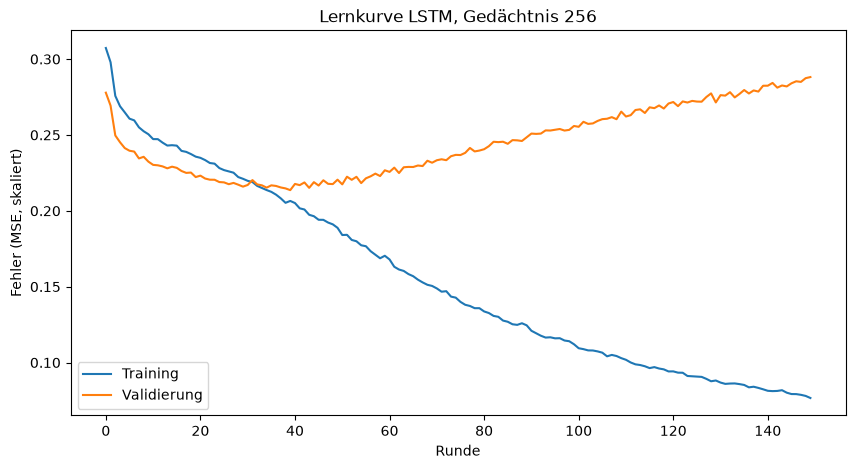

In [18]:
v = pd.DataFrame(verlauf)
ax = v.plot(x="runde", y=["training", "validierung"], figsize=(10, 5))
ax.set_title("Lernkurve LSTM, Gedächtnis 256")
ax.set_xlabel("Runde")
ax.set_ylabel("Fehler (MSE, skaliert)")
ax.legend(["Training", "Validierung"])

In [19]:
ax.figure.savefig(BILDER / "13_lernkurve_256.png", bbox_inches="tight")

In [20]:
v.loc[v["validierung"].idxmin()]

runde          39.000000
training        0.206509
validierung     0.213629
Name: 39, dtype: float64

Beste Runde 39, danach lernt das Modell auswendig.

### Early Stopping

Nach jeder Runde den besten Stand merken und nach 20 Runden ohne Verbesserung aufhören. Fertig eingebaut gibt es das in PyTorch nicht (nur in Zusatzpaketen wie Lightning oder skorch), deshalb von Hand wie im Team-Notebook 29. `copy` brauchen wir für eine echte Kopie der Gewichte:

In [21]:
import copy

torch.manual_seed(0)
modell = Vorhersage(kanaele=5, gedaechtnis=256).to(geraet)
fehler = torch.nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)

In [22]:
verlauf = []
bester_fehler = float("inf")
geduld = 0

for runde in range(300):
    modell.train()
    reihenfolge = torch.randperm(len(x_train), device=geraet)
    for start in range(0, len(x_train), 256):
        stapel = reihenfolge[start:start + 256]
        optimierer.zero_grad()
        loss = fehler(modell(x_train[stapel]), y_train[stapel])
        loss.backward()
        optimierer.step()

    modell.eval()
    with torch.no_grad():
        f_train = fehler(modell(x_train), y_train).item()
        f_val = fehler(modell(x_val), y_val).item()
    verlauf.append({"runde": runde, "training": f_train, "validierung": f_val})

    if f_val < bester_fehler:
        bester_fehler = f_val
        bester_stand = copy.deepcopy(modell.state_dict())
        beste_runde = runde
        geduld = 0
    else:
        geduld = geduld + 1
        if geduld == 20:
            print("Abbruch in Runde", runde)
            break

modell.load_state_dict(bester_stand)
print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))


Abbruch in Runde 59
beste Runde: 39   Validierungsfehler: 0.2136


Abbruch in Runde 59, genommen wird Runde 39.

### Vergleich mit der Messlatte

In °C, auf denselben Tagen wie das 7-Tage-Mittel aus Phase C:

In [23]:
x_test = torch.tensor(eingabe[ist_test], dtype=torch.float32, device=geraet)

with torch.no_grad():
    p_val = modell(x_val).cpu().numpy()
    p_test = modell(x_test).cpu().numpy()


In [24]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = info["tag"]

mittel7 = np.full((len(info), 24), np.nan)
for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7[gruppe.index] = w.loc[gruppe["tag"]].values


In [25]:
m7 = mittel7[morgen]
ok = ~np.isnan(m7).any(axis=1)
wahr = X_alle[morgen][:, :, 0]

for name, teil, p in [("Validierung", ist_val, p_val), ("Test", ist_test, p_test)]:
    o = ok[teil]
    lstm_grad = p[o] * streuung[0] + mittel[0]
    print(name, "LSTM:", np.abs(lstm_grad - wahr[teil][o]).mean().round(2),
          "  7 Tage:", np.abs(m7[teil][o] - wahr[teil][o]).mean().round(2))


Validierung LSTM: 5.07   7 Tage: 5.29
Test LSTM: 4.84   7 Tage: 4.28


Auf der Validierung schlägt das LSTM die Messlatte (5,07 gegen 5,29), im Test, dem Sommer 2024, verliert es (4,84 gegen 4,28). Wir probieren drei Ideen aus:

1. Dem LSTM 7 Tage zeigen statt einem
2. Nicht den Rücklauf selbst vorhersagen, sondern die Abweichung vom 7-Tage-Mittel
3. Auf allen HAST lernen statt nur auf den begangenen

Damit wir die Trainingsschleife nicht dreimal abschreiben, kommt sie in eine Funktion. Sie macht genau dasselbe wie oben: Gedächtnis 256, Early Stopping mit Geduld 20.

In [26]:
def trainiere(x_tr, y_tr, x_va, y_va):
    x_tr = torch.tensor(x_tr, dtype=torch.float32, device=geraet)
    y_tr = torch.tensor(y_tr, dtype=torch.float32, device=geraet)
    x_va = torch.tensor(x_va, dtype=torch.float32, device=geraet)
    y_va = torch.tensor(y_va, dtype=torch.float32, device=geraet)

    torch.manual_seed(0)
    modell = Vorhersage(kanaele=x_tr.shape[2], gedaechtnis=256).to(geraet)
    optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        modell.train()
        reihenfolge = torch.randperm(len(x_tr), device=geraet)
        for start in range(0, len(x_tr), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell(x_tr[stapel]), y_tr[stapel])
            loss.backward()
            optimierer.step()

        modell.eval()
        with torch.no_grad():
            f_val = fehler(modell(x_va), y_va).item()
        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(modell.state_dict())
            beste_runde = runde
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    modell.load_state_dict(bester_stand)
    print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))
    return modell

Vorhersagen machen wir in Stücken von 2048 Tagen, damit die Grafikkarte bei langen Eingaben nicht voll läuft:

In [27]:
def vorhersage(modell, x):
    ergebnis = []
    with torch.no_grad():
        for start in range(0, len(x), 2048):
            stueck = torch.tensor(x[start:start + 2048], dtype=torch.float32, device=geraet)
            ergebnis.append(modell(stueck).cpu().numpy())
    return np.concatenate(ergebnis)

Das LSTM von oben (1 Tag, Runde 39) für alle Paare, gleich in °C:

In [28]:
p_1 = vorhersage(modell, eingabe) * streuung[0] + mittel[0]

### Idee 1: Dem LSTM 7 Tage zeigen

Statt nur heute bekommt das LSTM heute und die 6 Tage davor, also 168 Stunden hintereinander. Dafür brauchen wir für jedes Paar die Zeilen der 6 Vortage derselben Station. `nummer` merkt sich, in welcher Zeile welcher Tag welcher Station steht:

In [29]:
nummer = {}
for i, (z, t) in enumerate(zip(info["zaehler"], info["tag"])):
    nummer[(z, t)] = i

reihen = []
for i in heute:
    z = info["zaehler"][i]
    t = info["tag"][i]
    reihen.append([nummer.get((z, t - pd.Timedelta(days=k)), -1) for k in range(6, -1, -1)])
reihen = np.array(reihen)

hat7 = (reihen >= 0).all(axis=1)
hat7.mean(), (hat7 == ok).all()

(np.float64(0.9065027232216537), np.True_)

Bei 91 % der Paare gibt es alle 6 Vortage. Das sind genau die Tage, an denen es auch das 7-Tage-Mittel gibt (`ok`). Fehlt ein Vortag, steht dort -1, diese Paare lassen wir weg.

Die 7 Tage hintereinanderhängen, ohne die Außentemperatur von morgen (die hat oben fast nichts gebracht):

In [30]:
eingabe7 = X_s[np.where(reihen >= 0, reihen, 0)].reshape(len(heute), 7 * 24, 4)
eingabe7.shape

(24236, 168, 4)

In [31]:
modell7 = trainiere(eingabe7[ist_train & hat7], ziel[ist_train & hat7], eingabe7[ist_val & hat7], ziel[ist_val & hat7])

beste Runde: 90   Validierungsfehler: 0.2096


In [32]:
p_7 = vorhersage(modell7, eingabe7) * streuung[0] + mittel[0]
p_7[~hat7] = np.nan

### Idee 2: Nur die Abweichung vom 7-Tage-Mittel vorhersagen

Das LSTM bekommt das 7-Tage-Mittel als sechsten Kanal und soll nur noch vorhersagen, wie weit morgen davon abweicht. Lernt es nichts, kommt genau die Messlatte raus.

In [33]:
m7_s = (np.nan_to_num(m7) - mittel[0]) / streuung[0]
eingabe_r = np.concatenate([eingabe, m7_s[:, :, None]], axis=2)
ziel_r = ziel - m7_s

In [34]:
modell_r = trainiere(eingabe_r[ist_train & ok], ziel_r[ist_train & ok], eingabe_r[ist_val & ok], ziel_r[ist_val & ok])

beste Runde: 32   Validierungsfehler: 0.2208


In [35]:
p_r = (vorhersage(modell_r, eingabe_r) + m7_s) * streuung[0] + mittel[0]
p_r[~ok] = np.nan

### Idee 3: Auf allen HAST lernen

Die Vorgabe der Betreuung ist, auf den begangenen HAST zu lernen (Notebook 29). Für die Vorhersage braucht man aber keine Labels, also könnte man auch alle Zähler nehmen. Dafür denselben Tensor wie in Phase C, nur für alle Zähler. Bei nicht begangenen Zählern ist das Ende der Stichtag:

In [36]:
from src.weather import load_outdoor_temperature

labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
labels["ende"] = labels["erste_begehung"].fillna(pd.Timestamp("2024-09-01")).clip(upper=pd.Timestamp("2024-09-01"))
ende = dict(zip(labels["zaehler"], labels["ende"]))

wetter = load_outdoor_temperature("2022-11-01", "2024-09-01")
wetter["tag"] = wetter["timestamp"].dt.date
wetter["stunde"] = wetter["timestamp"].dt.hour
aussen = wetter.pivot(index="tag", columns="stunde", values="t_out")

kanaele = {
    "ruecklauf": "Return temperature (°C)",
    "durchfluss": "Volume flow (l/h)",
    "vorlauf": "Flow temperature (°C)",
}

In [37]:
X_liste = []
info_liste = []

for datei in sorted(METER_DIR.glob("*.csv")):
    z = int(datei.stem)
    d = pd.read_csv(datei, parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < ende.get(z, pd.Timestamp("2024-09-01")))]
    d["tag"] = d["Timestamp"].dt.date
    d["stunde"] = d["Timestamp"].dt.hour

    tabellen = {}
    for name, spalte in kanaele.items():
        tabellen[name] = d.pivot(index="tag", columns="stunde", values=spalte)
    tabellen["aussen"] = aussen

    alle = pd.concat(tabellen, axis=1).dropna()
    if len(alle) == 0:
        continue
    X_liste.append(alle.values.reshape(len(alle), 4, 24).transpose(0, 2, 1))
    info_liste.append(pd.DataFrame({"zaehler": z, "tag": pd.to_datetime(alle.index)}))

X_hast = np.concatenate(X_liste)
info_hast = pd.concat(info_liste, ignore_index=True)
X_hast.shape, info_hast["zaehler"].nunique()

((42451, 24, 4), 94)

Gleiche Validierungswochen, gleicher Test, gleiche Skalierung wie bei den begangenen HAST, damit der Vergleich fair ist:

In [38]:
info_hast["woche"] = info_hast["tag"].dt.to_period("W").astype(str)
test_h = info_hast["tag"] >= "2024-06-01"
val_h = info_hast["woche"].isin(val_wochen) & ~test_h
train_h = ~test_h & ~val_h

naechster_h = info_hast.groupby("zaehler")["tag"].shift(-1)
heute_h = np.where((naechster_h - info_hast["tag"]) == pd.Timedelta(days=1))[0]
morgen_h = heute_h + 1

X_hast_s = (X_hast - mittel) / streuung
eingabe_h = np.concatenate([X_hast_s[heute_h], X_hast_s[morgen_h][:, :, 3:4]], axis=2)
ziel_h = X_hast_s[morgen_h][:, :, 0]
ist_train_h = train_h.values[morgen_h]
ist_train_h.sum()

np.int64(31730)

Gelernt wird auf allen HAST, das Early Stopping schaut aber auf dieselbe Validierung wie vorher (begangene HAST):

In [39]:
modell_h = trainiere(eingabe_h[ist_train_h], ziel_h[ist_train_h], eingabe[ist_val], ziel[ist_val])

beste Runde: 29   Validierungsfehler: 0.2134


In [40]:
p_h = vorhersage(modell_h, eingabe) * streuung[0] + mittel[0]

### Vergleich

Alles auf denselben Tagen (`ok`, also mit 7-Tage-Mittel), getrennt nach Validierung, den Sommertagen der Validierung (Mai bis September) und Test:

In [41]:
monat = info["tag"].dt.month.values[morgen]
sommer = np.isin(monat, [5, 6, 7, 8, 9])

varianten = {
    "7-Tage-Mittel (Messlatte)": m7,
    "LSTM, 1 Tag": p_1,
    "LSTM, 7 Tage Eingabe": p_7,
    "LSTM, Abweichung vom 7-Tage-Mittel": p_r,
    "LSTM, 1 Tag, alle HAST": p_h,
}

zeilen = []
for name, p in varianten.items():
    zeilen.append({
        "variante": name,
        "validierung": np.abs(p[ist_val & ok] - wahr[ist_val & ok]).mean(),
        "validierung_sommer": np.abs(p[ist_val & ok & sommer] - wahr[ist_val & ok & sommer]).mean(),
        "test": np.abs(p[ist_test & ok] - wahr[ist_test & ok]).mean(),
    })
vergleich = pd.DataFrame(zeilen)
vergleich.round(2)

,variante,validierung,validierung_sommer,test
0,7-Tage-Mittel (Messlatte),5.29,5.23,4.28
1,"LSTM, 1 Tag",5.07,4.98,4.84
2,"LSTM, 7 Tage Eingabe",5.02,4.90,4.77
3,"LSTM, Abweichung vom 7-Tage-Mittel",5.02,4.97,4.21
4,"LSTM, 1 Tag, alle HAST",5.10,5.01,4.76


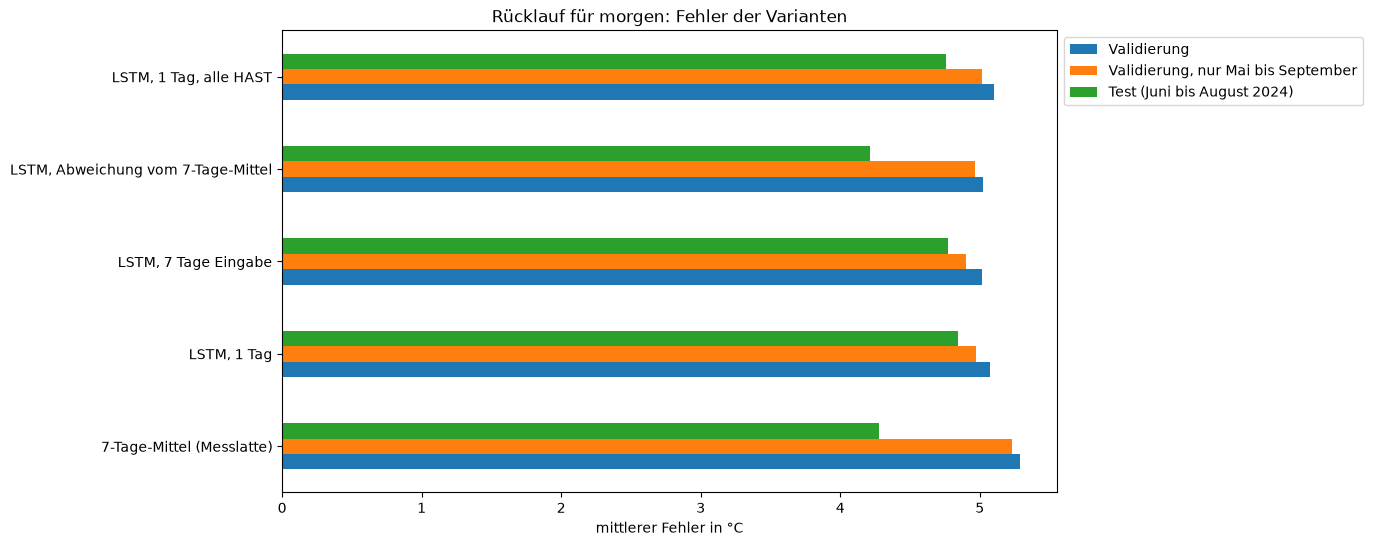

In [42]:
ax = vergleich.set_index("variante")[["validierung", "validierung_sommer", "test"]].plot.barh(figsize=(10, 6))
ax.set_title("Rücklauf für morgen: Fehler der Varianten")
ax.set_xlabel("mittlerer Fehler in °C")
ax.set_ylabel("")
ax.legend(["Validierung", "Validierung, nur Mai bis September", "Test (Juni bis August 2024)"],
          loc="upper left", bbox_to_anchor=(1, 1))

In [43]:
ax.figure.savefig(BILDER / "13_varianten.png", bbox_inches="tight")

- Alle LSTM-Varianten schlagen die Messlatte auf der Validierung, auch auf deren Sommertagen.
- Im Test (Sommer 2024) gewinnt nur die Abweichung vom 7-Tage-Mittel, und das knapp (4,21 gegen 4,28).
- Alle HAST bringen nichts gegenüber den begangenen. Wir bleiben bei der Vorgabe der Betreuung.
- 7 Tage Eingabe hilft auf der Validierung ein bisschen, im Test kaum.

Warum sagt die Validierung so wenig über den Test? An der Jahreszeit liegt es nicht, auch auf den Sommertagen der Validierung gewinnen alle LSTMs. Die Validierungswochen liegen aber zwischen Trainingswochen. Das Modell kennt die Woche davor und danach und muss nur eine Lücke füllen. Der Test liegt nach dem ganzen Training, da muss es wirklich in die Zukunft vorhersagen. Das ist wie bei den Nachbartagen in Schritt 11, nur mit Wochen.

Auswahl: Auf der Validierung liegen 7 Tage Eingabe und Abweichung gleichauf (5,02). Wir nehmen die Abweichung vom 7-Tage-Mittel, weil sie bei der Messlatte startet und eigentlich nur besser werden kann. Ehrlich dazu: Den Test haben wir dabei schon von allen Varianten gesehen. Für spätere Auswahlen wäre eine Validierung besser, die zeitlich nach dem Training liegt.

### Außentemperatur von morgen

Im Einsatz kennt man das Wetter von morgen nur aus der Vorhersage. Wie viel macht das aus? Einmal ganz ohne den fünften Kanal und einmal mit absichtlich verrauschter Temperatur, im Mittel 1,5 Grad daneben, ungefähr so gut wie eine Wettervorhersage für morgen:

In [44]:
modell_ohne_wetter = trainiere(eingabe[ist_train][:, :, :4], ziel[ist_train], eingabe[ist_val][:, :, :4], ziel[ist_val])
p_ohne = vorhersage(modell_ohne_wetter, eingabe[:, :, :4]) * streuung[0] + mittel[0]

beste Runde: 37   Validierungsfehler: 0.216


In [45]:
np.random.seed(1)
eingabe_rausch = eingabe.copy()
eingabe_rausch[:, :, 4] = eingabe_rausch[:, :, 4] + np.random.normal(0, 1.5 / streuung[3], size=(len(eingabe), 1))
p_rausch = vorhersage(modell, eingabe_rausch) * streuung[0] + mittel[0]

In [46]:
for name, p in [("mit Wetter von morgen", p_1), ("ohne Wetter von morgen", p_ohne), ("Wetter mit 1,5 Grad Fehler", p_rausch)]:
    print(name, "  Validierung:", np.abs(p[ist_val & ok] - wahr[ist_val & ok]).mean().round(2),
          "  Test:", np.abs(p[ist_test & ok] - wahr[ist_test & ok]).mean().round(2))

mit Wetter von morgen   Validierung: 5.07   Test: 4.84
ohne Wetter von morgen   Validierung: 5.13   Test: 4.8
Wetter mit 1,5 Grad Fehler   Validierung: 5.1   Test: 4.86


Ohne das Wetter von morgen oder mit 1,5 Grad Fehler ändert sich der Fehler nur um wenige Hundertstel Grad (Validierung 5,07 / 5,13 / 5,10, Test 4,84 / 4,80 / 4,86). Das Wetter von heute steckt schon in den 4 Kanälen, und morgen ist es meist ähnlich. Der fünfte Kanal bleibt drin, als Ersatz für die Wettervorhersage.

## Schritt 14: Engpass von 8 Zahlen

Für Phase E brauchen wir einen kurzen Steckbrief pro Tag. Der **Encoder** (LSTM) liest den Tag und presst ihn auf 8 Zahlen zusammen. Der **Decoder** bekommt nur diese 8 Zahlen und das Wetter von morgen und soll daraus Rücklauf, Durchfluss und Vorlauf von morgen vorhersagen. Klappt das, steckt in den 8 Zahlen, wie die Station tickt. Das ist das **Embedding**.

Alle drei Kanäle als Ziel, damit im Steckbrief auch der Durchfluss steckt. Beim Ventil sieht man den Fehler vor allem dort.

In [47]:
ziel3 = X_s[morgen][:, :, :3].reshape(len(heute), 72)
aussen_morgen = X_s[morgen][:, :, 3]

In [48]:
class Embedding(torch.nn.Module):
    def __init__(self, gedaechtnis, kern):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=4, hidden_size=gedaechtnis, batch_first=True)
        self.zum_kern = torch.nn.Linear(gedaechtnis, kern)
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(kern + 24, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 72),
        )

    def einbetten(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.zum_kern(h[-1])

    def forward(self, x, aussen):
        kern = self.einbetten(x)
        return self.decoder(torch.cat([kern, aussen], dim=1))

`zum_kern` ist der Engpass. `einbetten` gibt nur die 8 Zahlen zurück, die brauchen wir in Phase E. `ReLU` ist ein Knick, damit der Decoder nicht nur gerade Zusammenhänge lernen kann.

In [49]:
x_tr = torch.tensor(X_s[heute][ist_train], dtype=torch.float32, device=geraet)
a_tr = torch.tensor(aussen_morgen[ist_train], dtype=torch.float32, device=geraet)
y_tr = torch.tensor(ziel3[ist_train], dtype=torch.float32, device=geraet)
x_va = torch.tensor(X_s[heute][ist_val], dtype=torch.float32, device=geraet)
a_va = torch.tensor(aussen_morgen[ist_val], dtype=torch.float32, device=geraet)
y_va = torch.tensor(ziel3[ist_val], dtype=torch.float32, device=geraet)

In [50]:
torch.manual_seed(0)
modell_e = Embedding(gedaechtnis=256, kern=8).to(geraet)
optimierer = torch.optim.Adam(modell_e.parameters(), lr=0.001)
bester_fehler = float("inf")
geduld = 0

for runde in range(300):
    modell_e.train()
    reihenfolge = torch.randperm(len(x_tr), device=geraet)
    for start in range(0, len(x_tr), 256):
        stapel = reihenfolge[start:start + 256]
        optimierer.zero_grad()
        loss = fehler(modell_e(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
        loss.backward()
        optimierer.step()

    modell_e.eval()
    with torch.no_grad():
        f_val = fehler(modell_e(x_va, a_va), y_va).item()
    if f_val < bester_fehler:
        bester_fehler = f_val
        bester_stand = copy.deepcopy(modell_e.state_dict())
        beste_runde = runde
        geduld = 0
    else:
        geduld = geduld + 1
        if geduld == 20:
            break

modell_e.load_state_dict(bester_stand)
print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))


beste Runde: 59   Validierungsfehler: 0.1925


Zum Vergleich dasselbe ohne Engpass, mit 256 statt 8 Zahlen:

In [51]:
torch.manual_seed(0)
modell_256 = Embedding(gedaechtnis=256, kern=256).to(geraet)
optimierer = torch.optim.Adam(modell_256.parameters(), lr=0.001)
bester_fehler = float("inf")
geduld = 0

for runde in range(300):
    modell_256.train()
    reihenfolge = torch.randperm(len(x_tr), device=geraet)
    for start in range(0, len(x_tr), 256):
        stapel = reihenfolge[start:start + 256]
        optimierer.zero_grad()
        loss = fehler(modell_256(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
        loss.backward()
        optimierer.step()

    modell_256.eval()
    with torch.no_grad():
        f_val = fehler(modell_256(x_va, a_va), y_va).item()
    if f_val < bester_fehler:
        bester_fehler = f_val
        bester_stand = copy.deepcopy(modell_256.state_dict())
        beste_runde = runde
        geduld = 0
    else:
        geduld = geduld + 1
        if geduld == 20:
            break

modell_256.load_state_dict(bester_stand)
print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))

beste Runde: 59   Validierungsfehler: 0.1896


In echten Einheiten, für jeden der drei Kanäle:

In [52]:
w = ziel3[ist_val].reshape(-1, 24, 3)
for name, m in [("mit Engpass (8)", modell_e), ("ohne Engpass (256)", modell_256)]:
    with torch.no_grad():
        p = m(x_va, a_va).cpu().numpy().reshape(-1, 24, 3)
    f = np.abs(p - w).mean(axis=(0, 1)) * streuung[:3]
    print(name, "  Rücklauf:", f[0].round(2), "°C   Durchfluss:", f[1].round(1), "l/h   Vorlauf:", f[2].round(2), "°C")

mit Engpass (8)   Rücklauf: 5.22 °C   Durchfluss: 50.0 l/h   Vorlauf: 3.98 °C
ohne Engpass (256)   Rücklauf: 5.07 °C   Durchfluss: 50.5 l/h   Vorlauf: 3.88 °C


Mit Engpass ist der Validierungsfehler nur gut 1 % größer (0,1925 gegen 0,1896). Beim Rücklauf 5,22 statt 5,07 °C, beim Durchfluss und Vorlauf fast gleich. Fast alles, was das Modell über einen Tag wissen muss, passt in 8 Zahlen.

Die 8 Zahlen für jeden Tag, alle 24.684 und nicht nur die Paare. Gespeichert für Phase E, die Gewichte nach `notebooks/models/lernpfad/`:

In [53]:
teile = []
with torch.no_grad():
    for start in range(0, len(X_s), 4096):
        stueck = torch.tensor(X_s[start:start + 4096], dtype=torch.float32, device=geraet)
        teile.append(modell_e.einbetten(stueck).cpu().numpy())
emb = np.concatenate(teile)
emb.shape

(24684, 8)

In [54]:
np.save(LERNPFAD / "embedding_tage.npy", emb)

MODELLE = ROOT / "notebooks" / "models" / "lernpfad"
MODELLE.mkdir(parents=True, exist_ok=True)
torch.save(modell_e.state_dict(), MODELLE / "embedding_8.pt")


## Ergebnis Phase D

- Ein LSTM mit Early Stopping schlägt das 7-Tage-Mittel auf der Validierung. Im Test (Sommer 2024) nur, wenn es die Abweichung vom 7-Tage-Mittel vorhersagt (4,21 gegen 4,28).
- Die Validierung misst Lücken füllen zwischen Trainingswochen, der Test Vorhersage in die Zukunft. Für spätere Auswahlen ist eine Validierung besser, die zeitlich nach dem Training liegt.
- Alle HAST statt nur der begangenen bringen nichts.
- Ein Engpass von 8 Zahlen kostet bei der Vorhersage kaum etwas. Diese 8 Zahlen pro Tag (Embedding) sind gespeichert.

Ob in den 8 Zahlen etwas Sinnvolles über die Station steckt, prüfen wir in Phase E: Erkennt man damit dieselbe Station in einem anderen Zeitraum wieder, und findet eine logistische Regression damit die Befunde?